This notebook accompanies [14-neural-operators](https://xing-phys.github.io/ai-for-physics/14-neural-operators.html). Run cells from top to bottom. The web chapter provides typeset citations and numbered cross-references. Teaching code: MIT; text and figures: CC BY 4.0. All data are generated locally.


# Learning maps between physical fields 

::: {.callout-note}
## The physical question
Can we learn a reusable map from initial conditions, material properties, or sources to the resulting physical field, rather than solve one differential equation instance at a time?

You will distinguish functions from operators, derive DeepONet and Fourier layers, learn an exactly solvable diffusion-advection operator, and assess resolution transfer, conservation, stability, and the true cost of surrogate simulation.
:::

## A family of problems, rather than one answer

A conventional heat solver takes an initial temperature profile and computes its later evolution. Running it for one initial profile produces one solution. A neural operator instead attempts to approximate the mapping from an entire input function to an entire output function. The same learned parameters are reused when the initial profile changes. This is particularly attractive when a research problem requires thousands of solves, for example in uncertainty propagation, design optimization, or inference of an unknown material coefficient.

A **function** maps a coordinate to a number or vector, such as $u_0(x)$. An **operator** maps one function to another, such as $\mathcal G:u_0\mapsto u(\cdot,T)$. It is perfectly legitimate to store both functions as arrays on a computer. The important question is whether the learned construction approximates an underlying functional mapping or simply memorizes relationships between the entries of one fixed-size array.

Let $S_h$ sample a continuum function on a grid of spacing $h$, and let $I_h$ interpolate grid values back to a function. A discretized model $G_{\theta,h}$ is intended to satisfy

$$
I_hG_{\theta,h}S_h a\approx\mathcal G(a).
$$ 

Using the same $\theta$ on different grids is **parameter sharing across discretizations**. This makes resolution transfer possible, but does not establish convergence or correct prediction of unresolved physics. A model can run successfully on a finer grid and still be wrong there. Input sampling, quadrature, interpolation, geometry, and aliasing all affect the approximation.

## An exact operator to keep us honest

Consider the periodic interval $0\leq x<L$ and

$$
\partial_tu+c\partial_xu=\nu\partial_x^2u,
\qquad u(x,0)=a(x),\qquad \nu\geq0.
$$ 

Here $c$ is an advection velocity and $\nu$ a diffusivity. Periodicity means $u(0,t)=u(L,t)$ and matching spatial derivatives. Expand
$u(x,t)=\sum_{k\in\mathbb Z}\widehat u_k(t)e^{i\kappa_kx}$ with $\kappa_k=2\pi k/L$ and

$$
\widehat u_k(t)=\frac1L\int_0^L u(x,t)e^{-i\kappa_kx}\,dx.
$$

This coefficient formula follows by multiplying the expansion by $e^{-i\kappa_jx}$ and integrating: the integral of $e^{i(\kappa_k-\kappa_j)x}$ is $L$ if $k=j$ and zero otherwise. Substituting the expansion into the PDE gives one independent equation for each Fourier coefficient:

$$
\frac{d\widehat u_k}{dt}
=-(ic\kappa_k+\nu\kappa_k^2)\widehat u_k.
$$

Integrating this scalar equation yields

$$
\widehat u_k(T)=M_k(T)\widehat a_k,
\qquad M_k(T)=e^{-ic\kappa_kT-\nu\kappa_k^2T}.
$$ 

The phase factor translates the field, while the real exponential suppresses short wavelengths. The zero mode has $M_0=1$, so the spatial mean is conserved. Since $|M_k|\leq1$, the $L^2$ norm cannot increase. Pure advection, $\nu=0$, preserves every mode amplitude; diffusion, $\nu>0$, damps high frequencies most strongly.

The same conclusion follows in real space. Multiply the PDE by $u$, integrate, and use periodicity:

$$
\frac12\frac{d}{dt}\int_0^L u^2dx
=-\frac c2\int_0^L\partial_x(u^2)dx
+\nu[u\partial_xu]_0^L-\nu\int_0^L(\partial_xu)^2dx
=-\nu\int_0^L(\partial_xu)^2dx.
$$

This is an **energy estimate**, a bound on the size of solutions. Such estimates are valuable model diagnostics: a learned operator with $|M_k|>1$ in this example has introduced unphysical growth, even if the average test error is small.

## Learning a finite-rank functional expansion

Suppose we approximate the output field by a sum of $p$ basis functions:

$$
\mathcal G_\theta(a)(x)=\sum_{r=1}^p
b_r(a(x_1),\ldots,a(x_m))t_r(x)+b_0.
$$ 

A **branch network** computes the coefficients $b_r$ from input measurements at sensor locations $x_j$. A **trunk network** computes basis functions $t_r(x)$ at a requested output coordinate. Their inner product gives the prediction. This is the DeepONet construction [@p-lu2021]. The basis is learned jointly with the mapping from input measurements to coefficients.

There is nothing mysterious about the separation. In the exact heat solution, the Fourier functions are the basis and the initial Fourier coefficients multiplied by decay factors are the coefficients. A DeepONet learns a potentially nonlinear analogous expansion without requiring the correct analytic basis in advance. It can evaluate the output at coordinates not used during training because the trunk accepts a continuous coordinate. This is coordinate evaluation, not automatic recovery of arbitrary unseen fine structure.

Finite sensors impose a fundamental information limit. Two continuous functions can agree at all $m$ sensors and differ between them. The branch network receives identical inputs and must give identical coefficients. If the true operator responds differently to those functions, no training procedure can repair the ambiguity. Restricting the admissible inputs to a smooth or band-limited family, using enough sensors, or changing the input encoder addresses this issue. An approximation theorem always concerns a specified class of operators and inputs; it does not say that any finite sensor set identifies every function.

For a linear operator a fixed low-rank expansion resembles reduced-order modeling. One may use a singular-value decomposition of solution snapshots to identify dominant output modes. Neural expansions gain flexibility through nonlinear input encoding and learned coordinate dependence, but should be compared against such simpler reduced models. On a low-dimensional solution manifold, a carefully chosen linear basis can be both accurate and interpretable.

## Integral layers and the Fourier neural operator

An operator layer acts on a field of hidden features $v_\ell(x)$:

$$
v_{\ell+1}(x)=\sigma\left[
W_\ell v_\ell(x)+b_\ell(x)
+\int_D K_\ell(x,y)v_\ell(y)\,dy\right].
$$ 

Each feature channel is a function over space. $W_\ell$ mixes channels at the same point; the integral communicates information between points; $\sigma$ is a pointwise nonlinearity. The input can first be **lifted** from one physical scalar to several feature channels by a local network, and the final features **projected** back to the desired variables. Stacking these layers can represent nonlinear operators, not just linear Green functions [@p-kovachki2023].

On a uniform one-dimensional grid, an integral is approximated by
$h\sum_jK(x_i,x_j)v(x_j)$. Omitting $h$ changes the represented map as the grid is refined unless the weights or normalization compensate. On irregular points, quadrature weights encode area or volume associated with each point. A raw unweighted sum is generally a sum over the empirical point distribution rather than an approximation to a fixed physical integral.

If the kernel depends only on separation, $K(x,y)=K(x-y)$ on a periodic domain, the integral is a convolution. Insert a Fourier expansion $v(y)=\sum_k\widehat v_ke^{i\kappa_ky}$, and set $z=x-y$:

$$
\begin{aligned}
(Kv)(x)
&=\sum_k\widehat v_k\int K(x-y)e^{i\kappa_ky}\,dy\\
&=\sum_ke^{i\kappa_kx}
\left[\int K(z)e^{-i\kappa_kz}\,dz\right]\widehat v_k.
\end{aligned}
$$

Thus each Fourier coefficient is multiplied by the Fourier transform of the kernel. For several feature channels this multiplier is a small matrix $R_\ell(k)$. A Fourier neural operator layer computes

$$
v_{\ell+1}(x)=\sigma\left[W_\ell v_\ell(x)+b_\ell(x)
+\mathcal F^{-1}\{R_\ell(k)\widehat v_\ell(k)\}(x)\right].
$$ 

Only a selected set of low-frequency modes is usually assigned trainable matrices. Fast Fourier transforms make the spectral part cost roughly $N\log N$ rather than evaluating a dense $N\times N$ kernel. For real fields the coefficients obey $\widehat v_{-k}=\widehat v_k^*$; implementations must preserve the appropriate conjugate symmetry so that outputs are real.

The pointwise term and nonlinear activation are important. A truncated linear multiplier alone cannot represent nonlinear mode coupling. For example, squaring $u(x)=\cos kx$ creates a zero mode and a $2k$ mode because $\cos^2kx=[1+\cos2kx]/2$. Nonlinear layers can similarly mix frequencies. A grid with spacing $h$ resolves wavenumbers only up to the **Nyquist limit** $|\kappa|\leq\pi/h$. At sampled points $x_j=jh$, modes with wavenumbers $\kappa$ and $\kappa+2\pi n/h$ have identical values because $e^{i2\pi nj}=1$. Thus a generated higher frequency can appear as an incorrect lower frequency, a phenomenon called **aliasing**. Padding a spectral calculation before applying nonlinearities or filtering unresolved modes can control this effect, subject to the chosen discretization. Architectural resolution sharing does not make these numerical effects disappear.

The original FNO work studied Burgers, Darcy, and Navier–Stokes problems and demonstrated empirical resolution transfer and fast surrogate evaluation [@p-li2021fno]. Its reported speed comparisons refer to specified data, solvers, hardware, and tolerances. They should not be interpreted as a universal speed advantage over every well-tuned numerical method.

## A minimal trainable spectral operator

Our exact diffusion-advection example is linear and diagonal in Fourier space. We can therefore learn its multiplier without a large neural library. For training pairs $(a^{(n)},u^{(n)})$, minimize
$\sum_n|\widehat u_k^{(n)}-R_k\widehat a_k^{(n)}|^2$ at each mode. Differentiating with respect to the real and imaginary parts of $R_k$ gives

$$
R_k=\frac{\sum_n\widehat u_k^{(n)}\widehat a_k^{(n)*}}
{\sum_n|\widehat a_k^{(n)}|^2},
$$

provided the denominator is nonzero. Every mode must be excited by the training data. An absent mode is unidentified even in this completely favorable setting. The following code learns the real diffusion multiplier and applies it on a finer grid to inputs restricted to the frequencies that training resolved. It is the linear spectral core of an operator model, not a full nonlinear FNO.

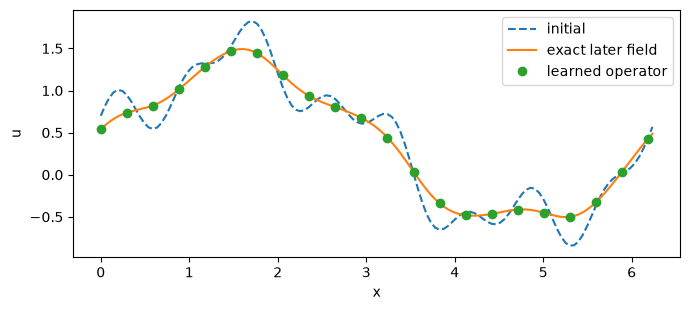

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1401)
L, nu, time, ntrain, cutoff = 2 * np.pi, 0.12, 0.4, 32, 10
xtrain = L * np.arange(ntrain) / ntrain
A = rng.normal(size=(60, ntrain))
Ak = np.fft.rfft(A, axis=1)
k = 2 * np.pi * np.fft.rfftfreq(ntrain, d=L/ntrain)
exact_multiplier = np.exp(-nu * time * k**2)
Uk = Ak * exact_multiplier
learned = (Uk * Ak.conj()).sum(axis=0) / (np.abs(Ak)**2).sum(axis=0)
assert np.allclose(learned.real, exact_multiplier)
assert np.max(np.abs(learned.imag)) < 1e-12

nfine = 128
x = L * np.arange(nfine) / nfine
initial = 0.4 + np.sin(x) + 0.3*np.cos(4*x) + 0.2*np.sin(8*x)
initial_k = np.fft.rfft(initial)
kfine = 2 * np.pi * np.fft.rfftfreq(nfine, d=L/nfine)
predicted_k = np.zeros_like(initial_k)
predicted_k[:cutoff+1] = initial_k[:cutoff+1] * learned[:cutoff+1]
prediction = np.fft.irfft(predicted_k, n=nfine)
truth = np.fft.irfft(initial_k * np.exp(-nu*time*kfine**2), n=nfine)
assert np.max(np.abs(prediction - truth)) < 1e-12
assert np.isclose(prediction.mean(), initial.mean())
assert np.linalg.norm(prediction) <= np.linalg.norm(initial)
plt.figure(figsize=(7, 3.2))
plt.plot(x, initial, "--", label="initial")
plt.plot(x, truth, label="exact later field")
plt.plot(x[::6], prediction[::6], "o", label="learned operator")
plt.xlabel("x"); plt.ylabel("u"); plt.legend(); plt.tight_layout(); plt.show()

If the test input includes $\sin(20x)$, it contains a physical wavelength absent from the 32-point training grid. Zeroing its learned output is an assumption, not a prediction justified by the training loss. Strong diffusion may make this missing contribution negligible at late times, while pure advection preserves it. The usefulness of resolution transfer depends on the PDE as well as the architecture.

## Conservation, stability, and error accumulation

A mass-conserving discretization writes updates as differences of fluxes. On a periodic one-dimensional grid,

$$
u_i^{n+1}=u_i^n-\frac{\Delta t}{h}
\left(F_{i+1/2}^n-F_{i-1/2}^n\right).
$$

Summing over $i$ cancels every internal flux, exactly conserving $h\sum_iu_i$. Learning the flux while keeping this difference structure preserves mass independently of network weights. A generic neural operator predicting the next field does not inherit this identity. Alternatively one can enforce the zero Fourier mode or project the prediction onto a fixed-mean subspace. Such projections preserve one constraint, but do not by themselves enforce positivity, entropy production, or local conservation.

Suppose a learned one-step map $\widetilde G$ approximates $G$ with local error at most $\epsilon$, and $G$ is **Lipschitz** with constant $K$ on the relevant states. This means $\|G(u)-G(v)\|\leq K\|u-v\|$: an input perturbation is amplified by at most $K$ in the selected norm. The local approximation bound must hold at the states reached by the learned rollout, not only at the exact trajectory. For rollout errors $e_n=\|\widetilde u_n-u_n\|$, insert and subtract $G(\widetilde u_n)$:

$$
e_{n+1}\leq\epsilon+Ke_n,
\qquad e_n\leq K^ne_0+\epsilon\sum_{j=0}^{n-1}K^j.
$$

If $K>1$, short-time errors can grow exponentially. If $K=1$, the bound grows linearly; if $K<1$, it saturates at $\epsilon/(1-K)$ after the initial error decays. These are bounds, not exact error laws, but they explain why one-step validation alone is inadequate. A chaotic system may have rapidly diverging trajectories yet accurate statistical observables; those two targets require different validation criteria.

The natural error metric also depends on the observable. Small field error in $L^2$ does not guarantee accurate gradients, stresses, dissipation, or rare extremes. A high-frequency perturbation $\delta u=\epsilon\sin kx$ has amplitude $\epsilon$ but derivative amplitude $k\epsilon$. Include derivative or spectral errors when the scientific question depends on them. Compare solutions at common physical resolutions and account for the accuracy of the reference solver.

## Frontier directions and useful comparisons

PDEBench provides data, baseline implementations, and varied PDE tasks that expose failures hidden by one convenient benchmark [@p-takamoto2022]. A benchmark is a controlled comparison instrument, not a substitute for checking a model on the actual boundary conditions, geometry, parameter regime, and observable of interest.

Recent operator research increasingly asks whether representations can transfer between equations. Universal Physics Transformers use a latent representation that is not tied to one grid or particle layout [@p-alkin2024]. Poseidon investigates pretraining and downstream adaptation across PDE tasks, including use of the semigroup structure of evolution [@p-herde2024]. These results support the empirical value of transferable representations; they do not prove universal generalization to arbitrary new equations. Transfer must be tested with clearly separated pretraining and downstream distributions.

A 2026 study organizes principles for converting familiar finite-dimensional architectures into function-space operators [@p-berner2026]. Its perspective reinforces the distinction developed here: a model should have a coherent continuum interpretation, while quadrature and discretization errors are controlled separately. Simply accepting arrays of several sizes is a weaker property.

For autonomous evolution, the exact solution operator obeys the semigroup property $\mathcal G_{t+s}=\mathcal G_t\circ\mathcal G_s$. One can train with different pairs of times or penalize violations of this relation. The relation is valid only when the represented state contains enough information for autonomous evolution. A projected density or coarse field with missing variables can have memory, so its effective dynamics need not form a semigroup. An apparent network failure may reveal an inadequate state description rather than insufficient capacity.

Classical alternatives include finite-volume and finite-element solvers, spectral methods, reduced-order bases, and multigrid. Hybrid approaches can learn closures, preconditioners, or coarse-grid corrections while preserving a trusted solver. An operator surrogate is most persuasive when it saves total cost over the required number of queries and when its error can be monitored. If training data generation costs $C_{\mathrm{data}}$, training costs $C_{\mathrm{train}}$, and each query saves $\Delta C$, break-even requires roughly
$(C_{\mathrm{data}}+C_{\mathrm{train}})/\Delta C$ queries. Reuse of existing data changes this accounting but does not eliminate model validation.

## Implementations to inspect

The [NeuralOperator library](https://github.com/neuraloperator/neuraloperator) provides implementations of spectral and other operator models. [PDEBench](https://github.com/pdebench/PDEBench) supplies benchmark data and baseline code, while the [Poseidon implementation](https://github.com/camlab-ethz/poseidon) connects pretraining to downstream tasks. The derivations and examples above are sufficient for this chapter; these projects are research extensions. Record a release or commit and its license when reusing software, because APIs, datasets, and model checkpoints evolve independently.

## Exercises and selected answers

1. **Traveling heat.** Solve @eq-physical-advection-diffusion for $a(x)=A\cos(2\pi x/L)$. Identify the decay rate and phase velocity.
2. **Sensor ambiguity.** On an evenly spaced sensor grid with $m$ points, construct a nonzero periodic function that vanishes at every sensor. Explain its implication for a branch network.
3. **Resolution stress test.** Add a $k=20$ mode to the demonstration and compare errors for $\nu=0$ and $\nu=0.12$. State exactly which modes the model learned.
4. **Mass correction.** Derive the least-squares correction to a predicted grid field subject to a prescribed spatial mean. Extend the answer to nonuniform quadrature weights.
5. **A scientific comparison.** Design a benchmark for predicting viscous dissipation. Explain why a low relative field error and a short evaluation time are insufficient reporting criteria.

**Answer to 1.** The solution is $A\exp[-\nu(2\pi/L)^2t]\cos[(2\pi/L)(x-ct)]$. The profile moves at speed $c$ while its amplitude decays at rate $\nu(2\pi/L)^2$.

**Answer to 2.** For sensors $x_j=jL/m$, $a(x)=\sin(2\pi mx/L)$ is zero at every sensor. The zero function has identical measurements. Their advection solutions differ, so no deterministic encoder of just those measurements can recover both exactly.

**Answer to 4.** On a uniform grid, subtract the predicted mean and add the target mean: $u_i^{\mathrm{corr}}=u_i-\bar u+\bar u_{\mathrm{target}}$. For the weighted norm $\sum_iw_i(\delta u_i)^2$ and weighted mean constraint, the minimizing correction is also constant. If one instead minimizes the unweighted Euclidean norm while imposing $\sum_iw_iu_i=M$, the correction is proportional to $w_i$: $\delta u_i=w_i(M-\sum_jw_ju_j)/\sum_jw_j^2$. The norm is part of the problem specification.